# UTS Graf Sains Data — Rekomendasi Berbasis Graf (RetailRocket × Neo4j)

**Nama / NIM:** _Ratu Arum Rahma Gati/23031554142_
**Dataset:** RetailRocket e-commerce `events.csv` (Roman Zykov, Kaggle)
**Neo4j:** Neo4j Desktop 2, instance `graf_sains_data` (server 2026.09, Cypher 25), database `neo4j`

| Fold | Periode (UTC, `[mulai, akhir)`) | Durasi |
|---|---|---|
| **P1 – training** | 2015-08-08 00:00:00 s/d sebelum 2015-08-22 00:00:00 | 14 hari |
| **P2 – testing**  | 2015-09-05 00:00:00 s/d sebelum 2015-09-12 00:00:00 | 7 hari |

**Alur notebook**
1. Tugas pendahuluan (tutorial driver Neo4j + jawaban checkpoint)
2. Wrangling: filter periode → `data/events_filtered.csv` → impor batch ke Neo4j
3. EDA: komposisi subgraph, VSM User, VSM Item, perbandingan proyeksi
4. Similarity (cosine item–item) → ditulis balik ke graf sebagai relasi `:SIMILAR`
5. Analytics: rekomendasi item-based KNN (k = 5) untuk user acak + Hit@5 & NDCG@5

## 0. Setup environment

```bash
uv venv myvenv --python 3.10        # atau: python -m venv myvenv
source myvenv/bin/activate
uv pip install -r requirements.txt
```

> **Catatan modifikasi `requirements.txt`.** File dari soal mem-pin `neo4j==4.2.1`, padahal kode tutorial memakai
> `driver.execute_query(...)` dan `RoutingControl` yang baru tersedia di driver **5.x ke atas**, dan server Neo4j Desktop 2
> sudah versi 2026.x. Karena itu driver di-upgrade ke versi terbaru. Paket IMDb (`imdbpy`, `cinemagoerng`, `imdbinfo`) dan `nose`
> tidak dipakai di UTS ini.

In [2]:
%pip install -q "neo4j>=5.20" pandas numpy scipy networkx matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, math, random, zipfile, subprocess
from collections import defaultdict

import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from neo4j import GraphDatabase, RoutingControl

URI      = "neo4j://127.0.0.1:7687"
AUTH     = ("neo4j", "gsd12345")
DB       = "neo4j"
DATA_DIR = "data"

P1_START, P1_END = "2015-08-08", "2015-08-22"   
P2_START, P2_END = "2015-09-05", "2015-09-12"   

EVENT_WEIGHT = {"view": 1, "addtocart": 3, "transaction": 5}  
BATCH_SIZE   = 5_000
SEED         = 42      
K_NEIGHBORS  = 5     
TOP_N        = 5      
N_ADS        = 3      
TOPK_WRITE   = 10    

random.seed(SEED); np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

## 1. Tugas Pendahuluan — driver Neo4j

Koneksi ke Neo4j memakai `GraphDatabase.driver` lalu `verify_connectivity()`.
Helper `run()` membungkus `driver.execute_query()` supaya hasilnya langsung jadi `DataFrame`.

In [3]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def run(query, read=False, **params):
    # Jalankan Cypher ke database DB, kembalikan pandas DataFrame.
    records, summary, keys = driver.execute_query(
        query, params, database_=DB,
        routing_=RoutingControl.READ if read else RoutingControl.WRITE,
    )
    return pd.DataFrame([r.data() for r in records], columns=keys)

print(run("CALL dbms.components() YIELD name, versions, edition RETURN name, versions, edition", read=True))
print(run("SHOW DATABASES YIELD name, currentStatus, default", read=True))

           name     versions     edition
0  Neo4j Kernel  [2026.09.0]  enterprise
1        Cypher      [5, 25]            
     name currentStatus  default
0   movie        online    False
1   neo4j        online     True
2  system        online    False


In [9]:
# --- Tutorial resmi (graf pertemanan Arthur) ---
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")
print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


**Jawaban Pertanyaan Pendahuluan (Checkpoint)**

1. **Nama database:** `neo4j` (parameter `database_="neo4j"`; ini juga *default database* instance).
2. **Akses database lain dalam 1 instance:**
   - `SHOW DATABASES` → melihat semua database (di instance ini: `neo4j`, `movie`, `system`);
   - klausa `USE <db>` di Cypher, mis. `USE movie MATCH (n) RETURN count(n)`;
   - perintah `:use movie` di Neo4j Browser/Query;
   - DDL administrasi (dijalankan di `system`): `CREATE DATABASE nama IF NOT EXISTS`, `STOP DATABASE nama`, `START DATABASE nama`, `DROP DATABASE nama`;
   - dari Python: `driver.session(database="movie")` atau `execute_query(..., database_="movie")`.
3. **Jenis graf pertemanan:** graf **berarah** (relasi `KNOWS` punya arah Arthur → teman), **tanpa bobot**, satu label node (`Person`) dan satu tipe relasi.
   Bentuknya **graf bintang (star graph, $K_{1,3}$)**: Arthur di pusat dengan 3 daun (Guinevere, Lancelot, Merlin). Karena `MERGE`, tidak ada node/relasi ganda.

**CYPHER total reset** sebelum masuk ke data RetailRocket:

In [10]:
def reset_database(chunk=10_000):
    # Truncate isi database bertahap supaya tidak kehabisan memori. HATI-HATI di shared database!
    total = 0
    while True:
        n = run("MATCH (n) WITH n LIMIT $chunk DETACH DELETE n RETURN count(*) AS c", chunk=chunk)["c"][0]
        total += n
        if n == 0:
            break
    print(f"Node terhapus: {total:,}")

reset_database()   # setara dengan: MATCH (n) DETACH DELETE n;

Node terhapus: 4


## 2.1 Wrangling dan EDA

### 2.1.1 – 2.1.2 Unduh data, filter `timestamp`, simpan `.csv`

`timestamp` pada `events.csv` adalah **unix epoch dalam milidetik (UTC)**. Batas periode dikonversi ke milidetik UTC,
lalu difilter dengan interval setengah terbuka `[start, end)` sehingga tidak ada event yang terhitung dua kali.

In [11]:
os.makedirs(DATA_DIR, exist_ok=True)
csv_path = os.path.join(DATA_DIR, "events.csv")
zip_path = "ecommerce-dataset.zip"

if not os.path.exists(csv_path):
    if not os.path.exists(zip_path):
        url = "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"
        subprocess.run(["curl", "-L", "-o", zip_path, url], check=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extract("events.csv", DATA_DIR)

events = pd.read_csv(csv_path)
events["datetime"] = pd.to_datetime(events["timestamp"], unit="ms", utc=True)
print(events.shape)
print("Rentang data:", events["datetime"].min(), "→", events["datetime"].max())
events.head()

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  290M  100  290M    0     0  1596k      0  0:03:06  0:03:06 --:--:--  129k


(2756101, 6)
Rentang data: 2015-05-03 03:00:04.384000+00:00 → 2015-09-18 02:59:47.788000+00:00


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106000+00:00


In [12]:
def to_ms(date_str):
    return int(pd.Timestamp(date_str, tz="UTC").timestamp() * 1000)

def in_period(df, start, end):
    return (df["timestamp"] >= to_ms(start)) & (df["timestamp"] < to_ms(end))

p1 = events[in_period(events, P1_START, P1_END)].assign(fold="P1")
p2 = events[in_period(events, P2_START, P2_END)].assign(fold="P2")
filtered = pd.concat([p1, p2]).sort_values("timestamp").reset_index(drop=True)

out_path = os.path.join(DATA_DIR, "events_filtered.csv")
filtered.drop(columns="datetime").to_csv(out_path, index=False)
print(f"Tersimpan: {out_path}  ({len(filtered):,} baris)")

ringkas = filtered.groupby("fold").agg(
    baris=("event", "size"),
    visitor=("visitorid", "nunique"),
    item=("itemid", "nunique"),
    mulai=("datetime", "min"),
    akhir=("datetime", "max"),
)
ringkas = ringkas.join(filtered.pivot_table(index="fold", columns="event", values="itemid", aggfunc="size", fill_value=0))
ringkas

Tersimpan: data/events_filtered.csv  (380,772 baris)


,baris,visitor,item,mulai,akhir,addtocart,transaction,view
fold,,,,,,,,
P1,245399,142047,73126,2015-08-08 00:00:04.851000+00:00,2015-08-21 23:59:59.243000+00:00,6421,2008,236970
P2,135373,78846,50105,2015-09-05 00:00:06.204000+00:00,2015-09-11 23:59:51.336000+00:00,3450,1080,130843


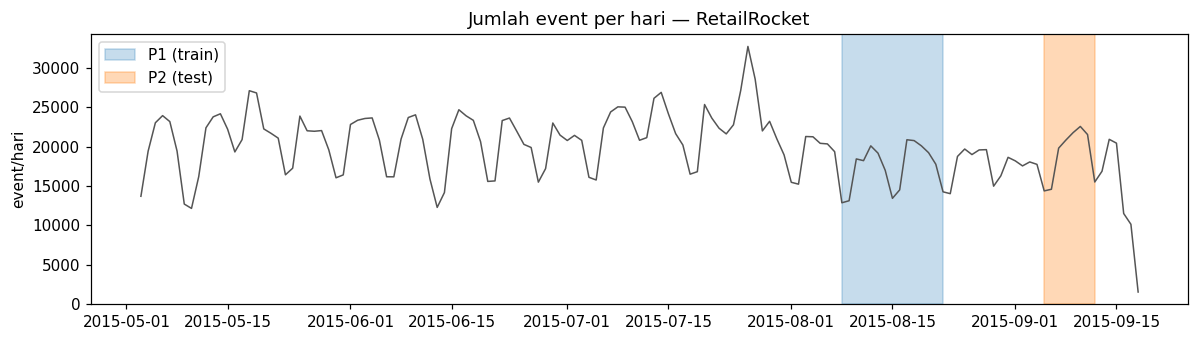

Visitor muncul di P1 & P2 : 2,134
Item muncul di P1 & P2    : 27,622


In [13]:
# Volume event harian + periode terpilih
daily = events.set_index("datetime").resample("D")["event"].size()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(daily.index, daily.values, color="#555", lw=1)
ax.axvspan(pd.Timestamp(P1_START, tz="UTC"), pd.Timestamp(P1_END, tz="UTC"), color="tab:blue", alpha=.25, label="P1 (train)")
ax.axvspan(pd.Timestamp(P2_START, tz="UTC"), pd.Timestamp(P2_END, tz="UTC"), color="tab:orange", alpha=.3, label="P2 (test)")
ax.set_title("Jumlah event per hari — RetailRocket"); ax.set_ylabel("event/hari"); ax.legend()
plt.tight_layout(); plt.show()

users_p1, users_p2 = set(p1.visitorid), set(p2.visitorid)
items_p1, items_p2 = set(p1.itemid), set(p2.itemid)
print(f"Visitor muncul di P1 & P2 : {len(users_p1 & users_p2):,}")
print(f"Item muncul di P1 & P2    : {len(items_p1 & items_p2):,}")

**Hasil filter (2.1.2).** Dari 2.756.101 event (2015-05-03 → 2015-09-18), tersaring **380.772 baris** ke `data/events_filtered.csv`:

| Fold | Baris | Visitor | Item | view | addtocart | transaction |
|---|---|---|---|---|---|---|
| P1 (14 hari) | 245.399 | 142.047 | 73.126 | 236.970 | 6.421 | 2.008 |
| P2 (7 hari) | 135.373 | 78.846 | 50.105 | 130.843 | 3.450 | 1.080 |

Hanya **2.134 visitor** yang muncul di P1 dan P2 (≈1,5% visitor P1), sedangkan **27.622 item** muncul di keduanya (≈37,8% item P1).
Artinya *item jauh lebih stabil antar waktu dibanding user* — fakta ini dipakai lagi di analisis proyeksi (2.1.6).

### Impor batch ke Neo4j

Modifikasi dari kode soal:
- Setiap relasi diberi properti **`fold`** (`'P1'`/`'P2'`), jadi satu graf memuat dua fold dan bisa dipisah lewat `WHERE r.fold = 'P1'`.
- Subquery `CALL { WITH ... UNION ALL ... }` (gaya *importing WITH*) sudah usang di Cypher 25, jadi pemisahan per jenis event
  dilakukan di Python: satu query `MERGE` node, lalu satu query `CREATE` per tipe relasi.
- Constraint `UNIQUE` pada `visitorId` dan `itemId` dibuat dulu supaya `MERGE`/`MATCH` memakai index (impor jauh lebih cepat).

In [14]:
REL_TYPE = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    tx.run(
        "UNWIND $batch AS row "
        "MERGE (:Visitor {visitorId: row.visitorid}) "
        "MERGE (:Item {itemId: row.itemid})",
        batch=batch,
    )
    for event, rel in REL_TYPE.items():
        rows = [r for r in batch if r["event"] == event]
        if not rows:
            continue
        extra = ", transactionId: row.transactionid" if event == "transaction" else ""
        tx.run(
            "UNWIND $rows AS row "
            "MATCH (v:Visitor {visitorId: row.visitorid}) "
            "MATCH (i:Item {itemId: row.itemid}) "
            f"CREATE (v)-[:{rel} {{timestamp: row.timestamp, fold: row.fold{extra}}}]->(i)",
            rows=rows,
        )

def to_records(chunk):
    # Konversi ke tipe Python murni + bersihkan NaN pada transactionid.
    return [
        {
            "timestamp": int(r.timestamp),
            "visitorid": int(r.visitorid),
            "event": str(r.event),
            "itemid": int(r.itemid),
            "transactionid": "" if pd.isna(r.transactionid) else str(int(r.transactionid)),
            "fold": r.fold,
        }
        for r in chunk.itertuples(index=False)
    ]

already = run("MATCH ()-[r]->() RETURN count(r) AS c", read=True)["c"][0]
if already > 0:
    print(f"Database sudah berisi {already:,} relasi → impor dilewati (jalankan reset_database() jika ingin impor ulang).")
else:
    with driver.session(database=DB) as session:
        create_constraints(session)
        print(f"Membaca file data dari: {out_path}")
        chunks = pd.read_csv(out_path, chunksize=BATCH_SIZE)
        total_rows = len(filtered)
        total_chunks = (total_rows // BATCH_SIZE) + 1
        print("Memulai proses impor data ke Neo4j...")
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
            session.execute_write(import_batch, to_records(chunk))
    print("Proses impor berhasil.")

Membaca file data dari: data/events_filtered.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/77 [00:00<?, ?it/s]

Proses impor berhasil.


### 2.1.3 Komposisi subgraph (Python API)

| Query | Penjelasan |
|---|---|
| `MATCH (n) RETURN labels(n)[0] AS label, count(*)` | `MATCH (n)` mengambil semua node; `labels(n)` mengembalikan list label, diambil elemen pertama, lalu dihitung per label (agregasi implisit seperti `GROUP BY`). |
| `MATCH ()-[r]->() RETURN type(r), r.fold, count(*)` | Pola relasi berarah tanpa syarat node; dikelompokkan per tipe relasi dan per fold. |
| `MATCH (v:Visitor)-[r]->() RETURN r.fold, count(DISTINCT v)` | Jumlah visitor unik yang aktif di tiap fold (`DISTINCT` karena satu visitor punya banyak relasi). |
| `MATCH (v:Visitor) RETURN COUNT { (v)-->() } AS deg` | *Count subquery* untuk menghitung derajat keluar setiap visitor → statistik derajat. |

In [15]:
komposisi_node = run("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah ORDER BY jumlah DESC", read=True)
komposisi_rel = run(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, r.fold AS fold, count(*) AS jumlah ORDER BY fold, jumlah DESC",
    read=True,
)
aktif_per_fold = run(
    "MATCH (v:Visitor)-[r]->(i:Item) "
    "RETURN r.fold AS fold, count(DISTINCT v) AS visitor_aktif, count(DISTINCT i) AS item_aktif, count(r) AS relasi "
    "ORDER BY fold",
    read=True,
)
display(komposisi_node, komposisi_rel, aktif_per_fold)

deg_v = run("MATCH (v:Visitor) RETURN COUNT { (v)-->() } AS deg", read=True)["deg"]
deg_i = run("MATCH (i:Item) RETURN COUNT { (i)<--() } AS deg", read=True)["deg"]
pd.DataFrame({"Visitor (out-degree)": deg_v.describe(), "Item (in-degree)": deg_i.describe()}).round(2)

,label,jumlah
0,Visitor,218759
1,Item,95609


,relasi,fold,jumlah
0,VIEWED,P1,236970
1,ADDED_TO_CART,P1,6421
2,BOUGHT,P1,2008
3,VIEWED,P2,130843
4,ADDED_TO_CART,P2,3450
5,BOUGHT,P2,1080


,fold,visitor_aktif,item_aktif,relasi
0,P1,142047,73126,245399
1,P2,78846,50105,135373


,Visitor (out-degree),Item (in-degree)
count,218759.00,95609.00
mean,1.74,3.98
std,6.76,10.69
min,1.00,1.00
25%,1.00,1.00
50%,1.00,2.00
75%,2.00,4.00
max,1513.00,1707.00


**Interpretasi komposisi subgraph.**
- **Jenis simpul:** 2 label — `Visitor` = **218.759** node dan `Item` = **95.609** node (total 314.368 node).
- **Jenis relasi:** 3 tipe, total **380.772** relasi (sama dengan jumlah baris `events_filtered.csv`, jadi impor lengkap):

| Relasi | P1 | P2 |
|---|---|---|
| `VIEWED` | 236.970 | 130.843 |
| `ADDED_TO_CART` | 6.421 | 3.450 |
| `BOUGHT` | 2.008 | 1.080 |

- Graf bersifat **bipartit, berarah, dan multigraf** (Visitor → Item, satu pasangan bisa punya beberapa relasi).
  Sekitar 96,6% relasi adalah `VIEWED`; `BOUGHT` hanya ±0,8% → pola *funnel* e-commerce.
- **Derajat:** median out-degree visitor = **1** (rata-rata 1,74, maks 1.513 — kemungkinan bot/crawler),
  median in-degree item = **2** (rata-rata 3,98, maks 1.707). Distribusinya *heavy-tailed*: sedikit node sangat aktif, mayoritas hanya 1–2 interaksi.

### 2.1.4 – 2.1.5 Vector Space Modelling (VSM)

Data training (fold **P1**) ditarik dari Neo4j, lalu dibentuk matriks interaksi berbobot
$R \in \mathbb{R}^{|U|\times|I|}$ dengan $R_{ui} = \sum (\text{view}=1,\ \text{addtocart}=3,\ \text{transaction}=5)$.

- **VSM User:** tiap user = vektor baris $R_{u,:}$ di ruang item → shape `(|U|, |I|)`.
- **VSM Item:** tiap item = vektor baris $R^\top_{i,:}$ di ruang user → shape `(|I|, |U|)`.

Cypher penarik data (agregasi bobot per pasangan visitor–item):
```cypher
MATCH (v:Visitor)-[r]->(i:Item) WHERE r.fold = 'P1'
RETURN v.visitorId AS visitor, i.itemId AS item,
       sum(CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS weight
```

In [4]:
Q_INTERAKSI = (
    "MATCH (v:Visitor)-[r]->(i:Item) WHERE r.fold = $fold "
    "RETURN v.visitorId AS visitor, i.itemId AS item, "
    "sum(CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS weight"
)
inter_p1 = run(Q_INTERAKSI, read=True, fold="P1")
inter_p2 = run(Q_INTERAKSI, read=True, fold="P2")
print(inter_p1.shape, inter_p2.shape)
inter_p1.head()

(196900, 3) (109833, 3)


,visitor,item,weight
0,1384233,466008,1
1,680354,466008,2
2,1068728,466008,1
3,644,466008,1
4,247235,466008,1


In [5]:
user_ids = np.sort(inter_p1["visitor"].unique())
item_ids = np.sort(inter_p1["item"].unique())
u_index = {u: k for k, u in enumerate(user_ids)}
i_index = {i: k for k, i in enumerate(item_ids)}

rows = inter_p1["visitor"].map(u_index).to_numpy()
cols = inter_p1["item"].map(i_index).to_numpy()
R = sp.csr_matrix((inter_p1["weight"].astype(float).to_numpy(), (rows, cols)),
                  shape=(len(user_ids), len(item_ids)))      # VSM User
RT = R.T.tocsr()                                              # VSM Item
B = (R > 0).astype(np.float32).tocsr()                        # versi biner (ada/tidak interaksi)

def karakteristik(M, nama, label_baris, label_kolom):
    deg = np.diff(M.indptr)
    nnz = M.nnz
    return pd.Series({
        "objek (baris)": label_baris,
        "dimensi (kolom)": label_kolom,
        "shape": M.shape,
        "jumlah dimensi": M.shape[1],
        "non-zero": nnz,
        "density": nnz / (M.shape[0] * M.shape[1]),
        "sparsity (%)": 100 * (1 - nnz / (M.shape[0] * M.shape[1])),
        "nnz per vektor (mean)": deg.mean(),
        "nnz per vektor (median)": np.median(deg),
        "nnz per vektor (max)": deg.max(),
        "% vektor dgn 1 nnz": 100 * (deg == 1).mean(),
        "memori CSR (MB)": (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6,
        "memori jika dense (GB)": M.shape[0] * M.shape[1] * 8 / 1e9,
    }, name=nama)

vsm_info = pd.concat([karakteristik(R, "VSM User", "User/Visitor", "Item"),
                      karakteristik(RT, "VSM Item", "Item", "User/Visitor")], axis=1)
vsm_info

,VSM User,VSM Item
objek (baris),User/Visitor,Item
dimensi (kolom),Item,User/Visitor
shape,"(142047, 73126)","(73126, 142047)"
jumlah dimensi,73126,142047
non-zero,196900,196900
density,0.000019,0.000019
sparsity (%),99.998104,99.998104
nnz per vektor (mean),1.386161,2.692613
nnz per vektor (median),1.0,1.0
nnz per vektor (max),671,1162


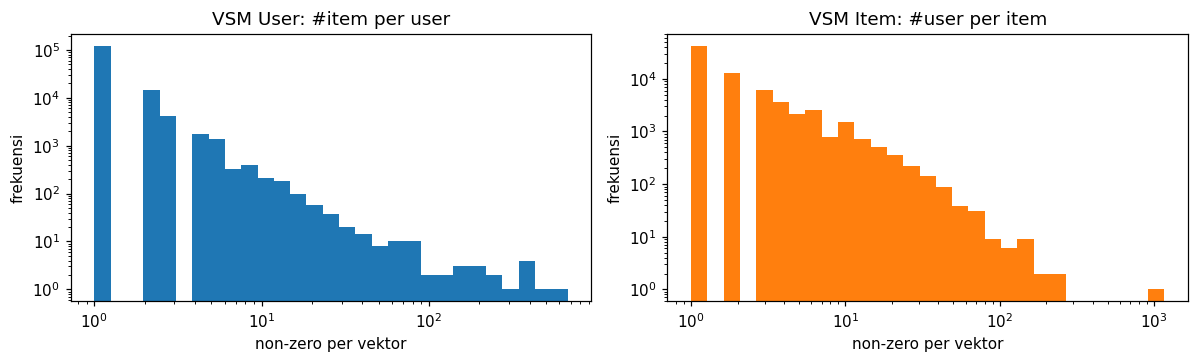

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, M, judul in [(axes[0], R, "VSM User: #item per user"), (axes[1], RT, "VSM Item: #user per item")]:
    deg = np.diff(M.indptr)
    bins = np.logspace(0, np.log10(deg.max() + 1), 30)
    ax.hist(deg, bins=bins, color="tab:blue" if M is R else "tab:orange")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(judul); ax.set_xlabel("non-zero per vektor"); ax.set_ylabel("frekuensi")
plt.tight_layout(); plt.show()

**Karakteristik VSM (2.1.4 & 2.1.5).**

| | VSM User | VSM Item |
|---|---|---|
| Objek / dimensi | user dalam ruang **73.126** item | item dalam ruang **142.047** user |
| Shape | (142.047 × 73.126) | (73.126 × 142.047) |
| Non-zero | 196.900 | 196.900 |
| Sparsity | 99,998% | 99,998% |
| nnz per vektor (mean / median / max) | 1,39 / 1 / 671 | 2,69 / 1 / 1.162 |
| Vektor dengan hanya 1 nnz | **83,7%** | 56,8% |

- Kedua matriks adalah transpose satu sama lain, jadi jumlah non-zero dan sparsity sama. Bedanya ada di **isi tiap vektor**.
- Matriks dense akan butuh ±83 GB, sedangkan CSR hanya ±3 MB → representasi **sparse wajib** dipakai.
- **83,7% vektor user hanya berisi 1 item** → profil user sangat miskin informasi. Vektor item rata-rata 2× lebih "kaya".
- Histogram log-log menunjukkan distribusi *power-law*; plot networkx sampel memperlihatkan proyeksi user cenderung
  membentuk klik-klik kecil yang terpisah, sedangkan proyeksi item lebih saling terhubung.

**Plot networkx.** Graf penuh terlalu besar untuk digambar, jadi diambil sampel acak (seed tetap) lalu digambar:
(kiri) graf bipartit Visitor–Item sampel, (kanan) **proyeksi** satu sisi (`nx.bipartite.weighted_projected_graph`):
dua user terhubung jika pernah berinteraksi dengan item yang sama (bobot = jumlah item bersama), dan sebaliknya untuk item.

In [20]:
def sample_bipartite(side, n=25, deg_min=2, deg_max=15, seed=SEED):
    # Ambil n node acak dari sisi 'user'/'item' dengan derajat di rentang tertentu + semua tetangganya.
    M = B if side == "user" else B.T.tocsr()
    deg = np.diff(M.indptr)
    kandidat = np.where((deg >= deg_min) & (deg <= deg_max))[0]
    rng = np.random.default_rng(seed)
    pilih = rng.choice(kandidat, size=min(n, len(kandidat)), replace=False)
    G = nx.Graph()
    for a in pilih:
        a_name = f"U{user_ids[a]}" if side == "user" else f"I{item_ids[a]}"
        G.add_node(a_name, bipartite=0)
        for b in M.indices[M.indptr[a]:M.indptr[a + 1]]:
            b_name = f"I{item_ids[b]}" if side == "user" else f"U{user_ids[b]}"
            G.add_node(b_name, bipartite=1)
            G.add_edge(a_name, b_name)
    top = [x for x, d in G.nodes(data=True) if d["bipartite"] == 0]
    return G, top

def plot_vsm(side):
    G, top = sample_bipartite(side)
    P = nx.bipartite.weighted_projected_graph(G, top)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    pos = nx.spring_layout(G, seed=SEED, k=0.35)
    warna = ["tab:blue" if n in set(top) else "tab:orange" for n in G]
    nx.draw_networkx(G, pos, ax=axes[0], node_color=warna, node_size=60, with_labels=False, width=.5)
    axes[0].set_title(f"Bipartit sampel ({len(top)} {side}, {G.number_of_nodes()-len(top)} tetangga)")
    pos2 = nx.spring_layout(P, seed=SEED)
    w = [P[a][b]["weight"] for a, b in P.edges()]
    nx.draw_networkx(P, pos2, ax=axes[1], node_color="tab:blue" if side == "user" else "tab:orange",
                     node_size=80, font_size=6, width=[0.5 + x for x in w])
    axes[1].set_title(f"Proyeksi {side}–{side}: {P.number_of_nodes()} node, {P.number_of_edges()} edge, "
                      f"density={nx.density(P):.3f}")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()
    return P

**VSM User — plot networkx**

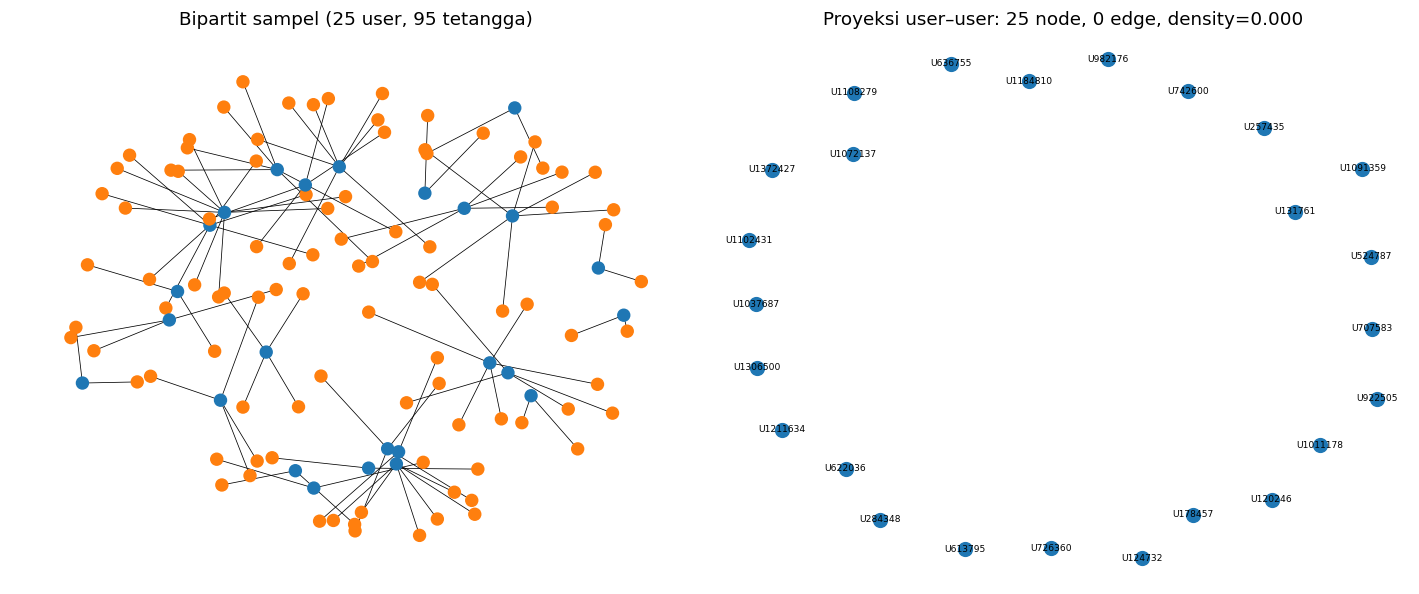

In [21]:
P_user_sample = plot_vsm("user")

**VSM Item — plot networkx**

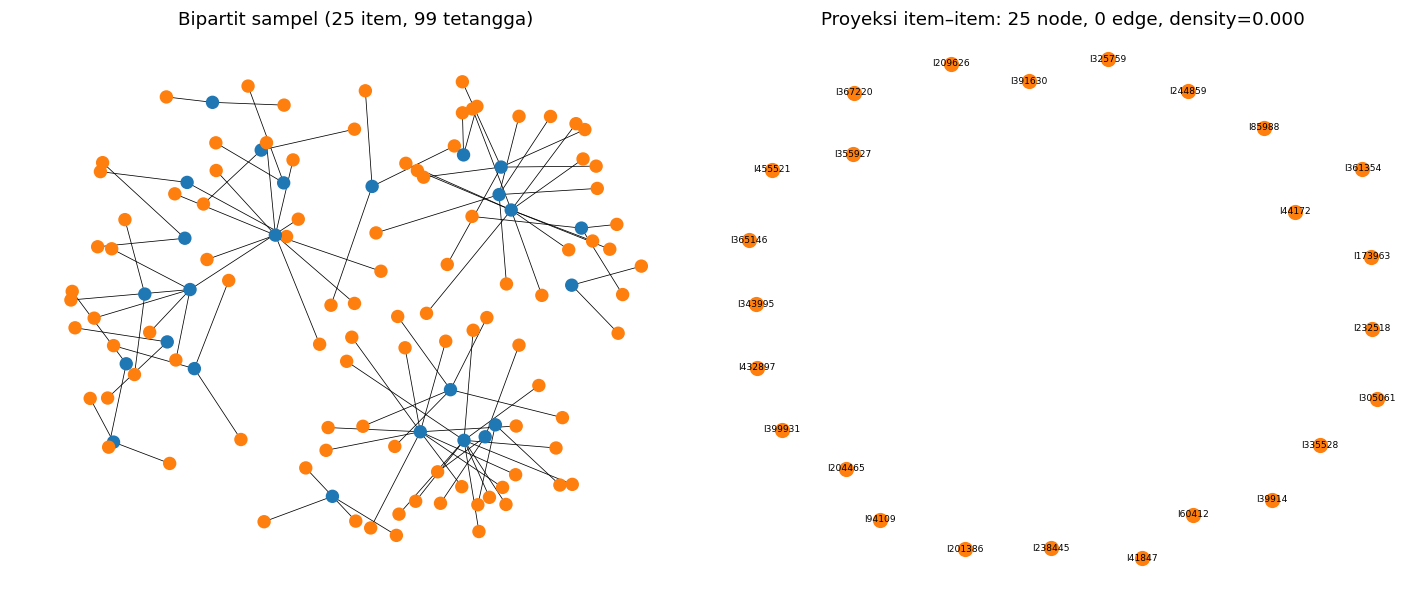

In [22]:
P_item_sample = plot_vsm("item")

### 2.1.6 Proyeksi mana yang lebih baik?

Proyeksi penuh dihitung dengan perkalian matriks biner:
- user–user: $A_U = B B^\top$ (ukuran $|U|\times|U|$)
- item–item: $A_I = B^\top B$ (ukuran $|I|\times|I|$)

Biaya komputasi sebanding dengan jumlah **wedge** (pasangan yang harus dibangkitkan):
proyeksi user membangkitkan $\sum_{i}\binom{d_i}{2}$ pasangan (item populer → ledakan pasangan),
proyeksi item membangkitkan $\sum_{u}\binom{d_u}{2}$ (kebanyakan user berderajat kecil).

In [23]:
def wedges(M):
    d = np.diff(M.indptr).astype(np.int64)
    return int((d * (d - 1) // 2).sum())

def proyeksi_info(M, nama, max_wedge=40_000_000):
    # M: matriks biner (node proyeksi = baris). Hitung graf proyeksi M M^T tanpa self-loop.
    w = wedges(M.T.tocsr())          # pasangan dibangkitkan lewat 'kolom' perantara
    n = M.shape[0]
    info = {"node": n, "wedge (biaya)": w}
    if w <= max_wedge:
        A = (M @ M.T).tocsr(); A.setdiag(0); A.eliminate_zeros()
        m = A.nnz // 2
        deg = np.diff(A.indptr)
        info.update({"edge": m, "density": 2 * m / (n * (n - 1)), "avg degree": deg.mean(),
                     "node terisolasi (%)": 100 * (deg == 0).mean(),
                     "memori adjacency (MB)": (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6,
                     "status": "dihitung penuh"})
    else:
        info.update({"edge": f"≤ {w:,}", "status": "terlalu besar, hanya estimasi"})
        A = None
    return pd.Series(info, name=nama), A

info_user, A_user = proyeksi_info(B, "Proyeksi User–User")
info_item, A_item = proyeksi_info(B.T.tocsr(), "Proyeksi Item–Item")
banding = pd.concat([info_user, info_item], axis=1)
banding

,Proyeksi User–User,Proyeksi Item–Item
node,142047,73126
wedge (biaya),1727076,1066404
edge,1700070,1027337
density,0.000169,0.000384
avg degree,23.936725,28.097722
node terisolasi (%),20.486177,51.814676
memori adjacency (MB),27.769312,16.7299
status,dihitung penuh,dihitung penuh


In [24]:
pilihan = "item" if info_item["wedge (biaya)"] <= info_user["wedge (biaya)"] else "user"
print(f"Biaya proyeksi user / item = {info_user['wedge (biaya)'] / max(info_item['wedge (biaya)'], 1):.1f}x")
print(f"→ Proyeksi yang dipakai untuk similarity: {pilihan.upper()}–{pilihan.upper()}")

Biaya proyeksi user / item = 1.6x
→ Proyeksi yang dipakai untuk similarity: ITEM–ITEM


**Analisis proyeksi (2.1.6).**

| Kriteria | User–User | Item–Item |
|---|---|---|
| Node | 142.047 | **73.126** |
| Wedge (biaya komputasi) | 1.727.076 | **1.066.404** |
| Edge | 1.700.070 | **1.027.337** |
| Memori adjacency | 27,8 MB | **16,7 MB** |
| Density | 0,000169 | **0,000384** |
| Rata-rata derajat | 23,9 | **28,1** |
| Node terisolasi | 20,5% | 51,8% |

- **Efisiensi:** proyeksi item ±1,6× lebih murah (wedge, edge, memori) dengan jumlah node setengahnya.
  Di dataset penuh (bukan 2 minggu) selisihnya makin besar karena item populer dengan $d$ viewer menghasilkan $\binom{d}{2}$ edge user–user.
- **Efektivitas:**
  1. Vektor item lebih kaya (rata-rata 2,69 vs 1,39 nnz) dan proyeksi item lebih padat (density 2,3× lebih tinggi, rata-rata derajat lebih besar), jadi similarity-nya dihitung dari lebih banyak bukti.
  2. **Item stabil antar periode:** 37,8% item P1 muncul lagi di P2, sedangkan visitor hanya 1,5%. Similarity user–user dari P1 hampir tidak bisa dipakai di P2 karena user-nya sudah tidak kembali.
  3. Kelemahan proyeksi item: 51,8% item terisolasi (hanya dilihat 1 user). Item ini tidak bisa direkomendasikan lewat similarity (*cold-start item*), tapi tidak mengganggu rekomendasi untuk item lain.
- **Kesimpulan:** proyeksi **Item–Item** lebih efektif dan efisien → dipakai untuk similarity (2.1.7) dan rekomendasi item-based KNN (2.2).

### 2.1.7 Similarity pada graf terproyeksi (Python)

Cosine similarity antar vektor item (VSM Item berbobot):
$$\text{sim}(a,b) = \frac{\vec{r}_a\cdot\vec{r}_b}{\lVert\vec{r}_a\rVert\,\lVert\vec{r}_b\rVert}$$
Hanya pasangan yang terhubung di proyeksi item–item (punya ≥ 1 user bersama) yang bernilai > 0.
Record acuan = **item paling populer di P1** (derajat terbesar), sehingga pemilihan acuan deterministik.

In [6]:
norms = np.sqrt(np.asarray(RT.multiply(RT).sum(axis=1)).ravel())
Xn = sp.diags(1.0 / np.where(norms == 0, 1, norms)) @ RT          # baris dinormalisasi L2
S = (Xn @ Xn.T).tocsr()
S.setdiag(0); S.eliminate_zeros()
print(f"Matriks similarity item–item: shape={S.shape}, pasangan>0 = {S.nnz // 2:,}")

def top_neighbors(S, k):
    # Top-k tetangga per item: dict idx -> list[(idx_tetangga, skor)], urut skor turun lalu id.
    hasil = {}
    for a in range(S.shape[0]):
        s, e = S.indptr[a], S.indptr[a + 1]
        if s == e:
            continue
        idx, val = S.indices[s:e], S.data[s:e]
        order = np.lexsort((item_ids[idx], -val))[:k]
        hasil[a] = [(int(idx[o]), float(val[o])) for o in order]
    return hasil

NB_WRITE = top_neighbors(S, TOPK_WRITE)
NB_K = {a: lst[:K_NEIGHBORS] for a, lst in NB_WRITE.items()}

ref_idx = int(np.argmax(np.diff(B.T.tocsr().indptr)))
REF_ITEM = int(item_ids[ref_idx])
top5_py = pd.DataFrame([(int(item_ids[b]), s) for b, s in NB_WRITE[ref_idx][:5]], columns=["item", "cosine_python"])
print(f"Item acuan: {REF_ITEM} (dilihat {np.diff(B.T.tocsr().indptr)[ref_idx]:,} user di P1)")
top5_py

Matriks similarity item–item: shape=(73126, 73126), pasangan>0 = 1,027,337
Item acuan: 187946 (dilihat 1,162 user di P1)


,item,cosine_python
0,127784,0.108708
1,459278,0.043550
2,38189,0.030795
3,248646,0.025144
4,133549,0.023096


#### 2.1.7(a) Cypher: 5 record dengan similarity tertinggi terhadap item acuan

Cosine dihitung langsung di Cypher dari graf bipartit (fold P1):
1. `MATCH (a)<-[r]-(v)` + `sum(...)` → bobot user terhadap item acuan ($r_{va}$).
2. Dari user yang sama, ke item lain `b` → bobot $r_{vb}$; `sum(wa*wb)` = dot product.
3. `CALL (x) { ... }` (subquery Cypher 25) menghitung norma vektor tiap item.
4. Urutkan skor, ambil 5 teratas.

In [7]:
CYPHER_TOP5 = '''
MATCH (a:Item {itemId: $ref})<-[r]-(v:Visitor)
WHERE r.fold = 'P1'
WITH a, v, sum(CASE type(r) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS wa
MATCH (v)-[r2]->(b:Item)
WHERE r2.fold = 'P1' AND b <> a
WITH a, b, v, wa, sum(CASE type(r2) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS wb
WITH a, b, sum(wa * wb) AS dot, count(v) AS user_bersama
CALL (a) {
  MATCH (a)<-[r]-(u:Visitor) WHERE r.fold = 'P1'
  WITH u, sum(CASE type(r) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS w
  RETURN sqrt(sum(w * w)) AS na
}
CALL (b) {
  MATCH (b)<-[r]-(u:Visitor) WHERE r.fold = 'P1'
  WITH u, sum(CASE type(r) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS w
  RETURN sqrt(sum(w * w)) AS nb
}
RETURN b.itemId AS item, user_bersama, round(dot / (na * nb), 6) AS cosine
ORDER BY cosine DESC, item ASC
LIMIT 5
'''
top5_cypher = run(CYPHER_TOP5, read=True, ref=REF_ITEM)
print(CYPHER_TOP5)
top5_cypher.merge(top5_py.round(6), on="item", how="left")   # verifikasi: hasil Cypher = hasil Python


MATCH (a:Item {itemId: $ref})<-[r]-(v:Visitor)
WHERE r.fold = 'P1'
WITH a, v, sum(CASE type(r) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS wa
MATCH (v)-[r2]->(b:Item)
WHERE r2.fold = 'P1' AND b <> a
WITH a, b, v, wa, sum(CASE type(r2) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS wb
WITH a, b, sum(wa * wb) AS dot, count(v) AS user_bersama
CALL (a) {
  MATCH (a)<-[r]-(u:Visitor) WHERE r.fold = 'P1'
  WITH u, sum(CASE type(r) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS w
  RETURN sqrt(sum(w * w)) AS na
}
CALL (b) {
  MATCH (b)<-[r]-(u:Visitor) WHERE r.fold = 'P1'
  WITH u, sum(CASE type(r) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS w
  RETURN sqrt(sum(w * w)) AS nb
}
RETURN b.itemId AS item, user_bersama, round(dot / (na * nb), 6) AS cosine
ORDER BY cosine DESC, item ASC
LIMIT 5



,item,user_bersama,cosine,cosine_python
0,127784,1,0.108708,0.108708
1,459278,1,0.043550,0.043550
2,38189,1,0.030795,0.030795
3,248646,1,0.025144,0.025144
4,133549,2,0.023096,0.023096


**Hasil 2.1.7(a).** Item acuan **187946** (item terpopuler P1, dilihat 1.162 user). 5 item termirip (cosine):

| Rank | Item | User bersama | Cosine |
|---|---|---|---|
| 1 | 127784 | 1 | 0,108708 |
| 2 | 459278 | 1 | 0,043550 |
| 3 | 38189 | 1 | 0,030795 |
| 4 | 248646 | 1 | 0,025144 |
| 5 | 133549 | 2 | 0,023096 |

Nilai Cypher **identik** dengan perhitungan Python (kolom `cosine_python`), jadi query tervalidasi.
Skornya kecil karena item acuan sangat populer (norma vektornya besar) sementara tiap tetangga hanya berbagi 1–2 user.
Ini juga menunjukkan bahwa cosine pada data sparse sensitif terhadap item dengan sedikit interaksi.

#### 2.1.7(b) Tulis kembali similarity ke graf

Untuk setiap item, `TOPK_WRITE` tetangga paling mirip disimpan sebagai relasi `(:Item)-[:SIMILAR {score}]->(:Item)`.
Pasangan dideduplikasi (a < b) sehingga satu pasangan = satu relasi; query membacanya tanpa arah `-[:SIMILAR]-`.

In [27]:
run("MATCH ()-[s:SIMILAR]->() DELETE s")          # bersihkan hasil run sebelumnya

pairs = {}
for a, lst in NB_WRITE.items():
    for b, s in lst:
        x, y = sorted((int(item_ids[a]), int(item_ids[b])))
        pairs[(x, y)] = round(s, 6)
sim_rows = [{"a": x, "b": y, "score": s} for (x, y), s in pairs.items()]
print(f"Relasi SIMILAR yang akan ditulis: {len(sim_rows):,}")

for k in tqdm(range(0, len(sim_rows), BATCH_SIZE), desc="Menulis SIMILAR"):
    run(
        "UNWIND $rows AS row "
        "MATCH (a:Item {itemId: row.a}) MATCH (b:Item {itemId: row.b}) "
        "CREATE (a)-[:SIMILAR {score: row.score, metric: 'cosine', fold: 'P1'}]->(b)",
        rows=sim_rows[k:k + BATCH_SIZE],
    )

hasil_tulis = run(
    "MATCH (a:Item {itemId: $ref})-[s:SIMILAR]-(b:Item) "
    "RETURN a.itemId AS acuan, b.itemId AS item, s.score AS score "
    "ORDER BY score DESC, item ASC LIMIT 5",
    read=True, ref=REF_ITEM,
)
print(run("MATCH ()-[s:SIMILAR]->() RETURN count(s) AS jumlah_SIMILAR", read=True))
hasil_tulis

Relasi SIMILAR yang akan ditulis: 128,640


Menulis SIMILAR:   0%|          | 0/26 [00:00<?, ?it/s]

   jumlah_SIMILAR
0          128640


,acuan,item,score
0,187946,127784,0.108708
1,187946,459278,0.043550
2,187946,38189,0.030795
3,187946,248646,0.025144
4,187946,133549,0.023096


**Hasil 2.1.7(b).** Sebanyak **128.640** relasi `SIMILAR` (top-10 tetangga per item, sudah dideduplikasi) ditulis ke graf.
Query baca-balik untuk item 187946 mengembalikan 5 skor yang sama persis dengan hasil 2.1.7(a), jadi nilai similarity berhasil tersimpan di graf.

Query yang dipakai untuk memperlihatkan hasil penulisan:
```cypher
MATCH (a:Item {itemId: $ref})-[s:SIMILAR]-(b:Item)
RETURN a.itemId AS acuan, b.itemId AS item, s.score AS score
ORDER BY score DESC, item ASC LIMIT 5
```

### 2.1.8 Graf sebelum vs sesudah perhitungan similarity

**Sebelum** — item acuan dan 5 item termirip hanya terhubung *tidak langsung* lewat visitor (pola 2-hop Item ← Visitor → Item):
```cypher
MATCH p = (a:Item {itemId: $ref})<-[r1]-(v:Visitor)-[r2]->(b:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND b.itemId IN $top5
RETURN p LIMIT 60
```
**Sesudah** — item acuan terhubung *langsung* ke item termirip lewat relasi `SIMILAR` berbobot:
```cypher
MATCH p = (a:Item {itemId: $ref})-[s:SIMILAR]-(b:Item)
RETURN p ORDER BY s.score DESC LIMIT 5
```
➡️ Jalankan kedua query di **Neo4j Desktop → Query** (ganti `$ref` dan `$top5` dengan nilai yang dicetak sel berikut),
pilih tampilan **Graph**, lalu screenshot dan simpan ke folder `img/`. Sel di bawah menggambar versi networkx-nya.

:param ref => 187946;
:param top5 => [127784, 459278, 38189, 248646, 133549];


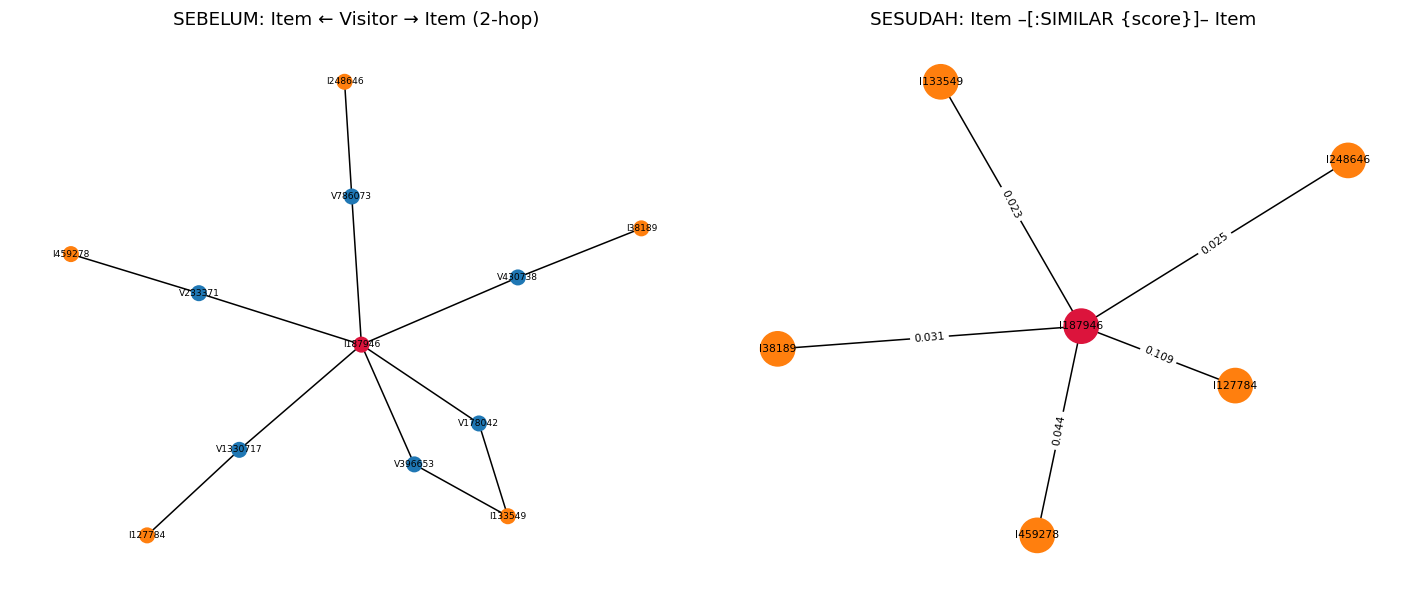

In [8]:
TOP5_IDS = top5_py["item"].tolist()
print(f":param ref => {REF_ITEM};")
print(f":param top5 => {TOP5_IDS};")

before = run(
    "MATCH (a:Item {itemId: $ref})<-[r1]-(v:Visitor)-[r2]->(b:Item) "
    "WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND b.itemId IN $top5 "
    "RETURN DISTINCT v.visitorId AS visitor, b.itemId AS item LIMIT 60",
    read=True, ref=REF_ITEM, top5=TOP5_IDS,
)
after = run(
    "MATCH (a:Item {itemId: $ref})-[s:SIMILAR]-(b:Item) "
    "RETURN b.itemId AS item, s.score AS score ORDER BY score DESC LIMIT 5",
    read=True, ref=REF_ITEM,
)

G_before = nx.Graph()
for row in before.itertuples():
    G_before.add_edge(f"I{REF_ITEM}", f"V{row.visitor}"); G_before.add_edge(f"V{row.visitor}", f"I{row.item}")
G_after = nx.Graph()
for row in after.itertuples():
    G_after.add_edge(f"I{REF_ITEM}", f"I{row.item}", weight=row.score)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
def warna(G): return ["crimson" if n == f"I{REF_ITEM}" else ("tab:orange" if n.startswith("I") else "tab:blue") for n in G]
nx.draw_networkx(G_before, nx.spring_layout(G_before, seed=SEED), ax=axes[0], node_color=warna(G_before), node_size=90, font_size=6)
axes[0].set_title("SEBELUM: Item ← Visitor → Item (2-hop)")
pos = nx.spring_layout(G_after, seed=SEED)
nx.draw_networkx(G_after, pos, ax=axes[1], node_color=warna(G_after), node_size=500, font_size=7)
nx.draw_networkx_edge_labels(G_after, pos, ax=axes[1], font_size=7,
                             edge_labels={(a, b): f"{d['weight']:.3f}" for a, b, d in G_after.edges(data=True)})
axes[1].set_title("SESUDAH: Item –[:SIMILAR {score}]– Item")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

**Hasil 2.1.8.** Parameter: `ref = 187946`, `top5 = [127784, 459278, 38189, 248646, 133549]`.
- **Sebelum:** item acuan dan item lain hanya terhubung tidak langsung lewat visitor (2-hop). Untuk tahu kemiripannya,
  harus menelusuri semua visitor setiap kali query dijalankan.
- **Sesudah:** item acuan terhubung **langsung** (1-hop) ke 5 item termirip lewat `SIMILAR {score}`.
  Rekomendasi cukup membaca relasi ini tanpa menghitung ulang.

Screenshot dari Neo4j Desktop: `img/sebelum_similarity.png` dan `img/sesudah_similarity.png`.

   <table>
   <tr><th>Sebelum similarity</th><th>Sesudah similarity</th></tr>
   <tr>
   <td><img src="img/sebelum_similarity.png" width="420"></td>
   <td><img src="img/sesudah_similarity.png" width="420"></td>
   </tr>
   </table>

## 2.2 Analytics

### 2.2.1 Pemilihan user acak (reproducible) & rekomendasi KNN

**Proses acak:**
1. Kandidat = user yang (i) punya ≥ 2 item berbeda di P1 (supaya punya profil) dan (ii) punya ≥ 1 interaksi di P2 (supaya bisa dievaluasi).
2. Kandidat diurutkan berdasarkan `visitorId` (urutan deterministik, tidak tergantung urutan baca data).
3. `random.Random(SEED).choice(kandidat)` dengan `SEED = 42` → hasil selalu sama setiap kali notebook dijalankan.

**Item-based KNN (k = 5):** untuk setiap item $j$ yang dilihat user di P1, ambil $k=5$ tetangga terdekat $N_k(j)$ dari proyeksi
item–item (cosine). Skor kandidat:
$$\text{score}(u, i) = \sum_{j \in I_u,\ i \in N_k(j)} \text{sim}(i, j)\cdot r_{uj}$$
Item yang sudah dilihat user di P1 dibuang, lalu diurutkan → top-5 = list rekomendasi, top-3 = item yang **diiklankan**.

In [29]:
gt = inter_p2.groupby("visitor")["item"].apply(set).to_dict()     # ground truth P2
user_deg = np.diff(B.indptr)
kandidat = sorted(int(u) for u in user_ids[user_deg >= 2] if int(u) in gt)
print(f"Jumlah kandidat user: {len(kandidat):,}")

rng_user = random.Random(SEED)
USER = rng_user.choice(kandidat)
u_idx = u_index[USER]
print(f"User terpilih: {USER}")

riwayat = inter_p1[inter_p1["visitor"] == USER].sort_values("weight", ascending=False)
print("Riwayat P1 user (item, bobot):"); display(riwayat)
print("Item yang disentuh user di P2 (ground truth):", sorted(gt[USER]))

Jumlah kandidat user: 792
User terpilih: 1166607
Riwayat P1 user (item, bobot):


,visitor,item,weight
58641,1166607,351626,1
59345,1166607,290003,1


Item yang disentuh user di P2 (ground truth): [383176, 402614]


In [30]:
def knn_recommend(u_idx, k=K_NEIGHBORS, n=TOP_N, exclude_seen=True):
    # Item-based KNN: agregasi skor dari k tetangga terdekat setiap item yang pernah disentuh user.
    s, e = R.indptr[u_idx], R.indptr[u_idx + 1]
    seen, w_seen = R.indices[s:e], R.data[s:e]
    seen_set = set(seen.tolist())
    skor, alasan = defaultdict(float), defaultdict(list)
    for j, r_uj in zip(seen, w_seen):
        for i, sim in NB_WRITE.get(int(j), [])[:k]:
            if exclude_seen and i in seen_set:
                continue
            skor[i] += sim * r_uj
            alasan[i].append(int(item_ids[j]))
    ranked = sorted(skor.items(), key=lambda x: (-x[1], item_ids[x[0]]))[:n]
    return pd.DataFrame(
        [(rank + 1, int(item_ids[i]), sc, alasan[i]) for rank, (i, sc) in enumerate(ranked)],
        columns=["rank", "item", "score", "karena_melihat"],
    )

rekom = knn_recommend(u_idx)
rekom["relevan_di_P2"] = rekom["item"].isin(gt[USER]).astype(int)
print(f"Top-{TOP_N} rekomendasi KNN (k={K_NEIGHBORS}) untuk user {USER}:")
display(rekom)
iklan = rekom.head(N_ADS)
print(f"\n>>> {N_ADS} item yang DIIKLANKAN: {iklan['item'].tolist()}")

Top-5 rekomendasi KNN (k=5) untuk user 1166607:


,rank,item,score,karena_melihat,relevan_di_P2
0,1,36283,0.521862,[290003],0
1,2,169431,0.408248,[351626],0
2,3,358485,0.391397,[290003],0
3,4,369981,0.336861,[290003],0
4,5,296795,0.196589,[351626],0



>>> 3 item yang DIIKLANKAN: [36283, 169431, 358485]


**Jawaban 2.2.1(b).** User terpilih: **1166607** (dari 792 kandidat, `random.Random(42)`). Riwayat P1: item 351626 dan 290003 (masing-masing *view*).

| Rank | Item | Skor | Karena melihat |
|---|---|---|---|
| 1 | **36283** | 0,5219 | 290003 |
| 2 | **169431** | 0,4082 | 351626 |
| 3 | **358485** | 0,3914 | 290003 |
| 4 | 369981 | 0,3369 | 290003 |
| 5 | 296795 | 0,1966 | 351626 |

➡️ **3 item yang diiklankan (k = 5): 36283, 169431, 358485.**
Versi Cypher (dari relasi `SIMILAR`) menghasilkan urutan dan skor yang sama.

Versi graph-native (opsional): rekomendasi yang sama bisa ditarik dari relasi `SIMILAR` di Neo4j.
Karena yang disimpan adalah top-10 tetangga, skornya bisa sedikit berbeda dari versi Python yang memakai tepat k = 5.
```cypher
MATCH (u:Visitor {visitorId: $user})-[r]->(j:Item) WHERE r.fold = 'P1'
WITH u, j, sum(CASE type(r) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS r_uj
MATCH (j)-[s:SIMILAR]-(i:Item)
WHERE NOT EXISTS { (u)-[x]->(i) WHERE x.fold = 'P1' }
RETURN i.itemId AS item, sum(s.score * r_uj) AS score
ORDER BY score DESC LIMIT 5
```

In [31]:
rekom_cypher = run(
    "MATCH (u:Visitor {visitorId: $user})-[r]->(j:Item) WHERE r.fold = 'P1' "
    "WITH u, j, sum(CASE type(r) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS r_uj "
    "MATCH (j)-[s:SIMILAR]-(i:Item) "
    "WHERE NOT EXISTS { (u)-[x]->(i) WHERE x.fold = 'P1' } "
    "RETURN i.itemId AS item, sum(s.score * r_uj) AS score ORDER BY score DESC LIMIT 5",
    read=True, user=USER,
)
rekom_cypher

,item,score
0,36283,0.521862
1,169431,0.408248
2,358485,0.391397
3,369981,0.336861
4,296795,0.196589


### 2.2.2 Evaluasi: Hit@5 dan NDCG@5

Ground truth = himpunan item yang disentuh user di **P2**. Relevansi biner: $rel_i = 1$ jika item ke-$i$ ada di P2.

$$\text{Hit@5} = \mathbb{1}\left[\sum_{i=1}^{5} rel_i > 0\right]
\qquad
\text{DCG@5} = \sum_{i=1}^{5}\frac{rel_i}{\log_2(i+1)}
\qquad
\text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}$$

IDCG@5 = DCG dari urutan ideal (semua item relevan di posisi teratas, sebanyak $\min(|GT|, 5)$).

In [32]:
def hit_at_k(rec_items, truth, k=5):
    return int(any(i in truth for i in rec_items[:k]))

def ndcg_at_k(rec_items, truth, k=5):
    rel = [1 if i in truth else 0 for i in rec_items[:k]]
    dcg = sum(r / math.log2(pos + 2) for pos, r in enumerate(rel))
    idcg = sum(1 / math.log2(pos + 2) for pos in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0

rec_items = rekom["item"].tolist()
truth = gt[USER]
tabel = pd.DataFrame({
    "rank i": range(1, len(rec_items) + 1),
    "item": rec_items,
    "rel_i": [int(x in truth) for x in rec_items],
})
tabel["1/log2(i+1)"] = 1 / np.log2(tabel["rank i"] + 1)
tabel["kontribusi DCG"] = tabel["rel_i"] * tabel["1/log2(i+1)"]
display(tabel.round(4))

HIT5, NDCG5 = hit_at_k(rec_items, truth), ndcg_at_k(rec_items, truth)
idcg = sum(1 / math.log2(p + 2) for p in range(min(len(truth), 5)))
print(f"|GT P2| = {len(truth)}  →  IDCG@5 = {idcg:.4f}")
print(f"DCG@5  = {tabel['kontribusi DCG'].sum():.4f}")
print(f"Hit@5  = {HIT5}")
print(f"NDCG@5 = {NDCG5:.4f}")

,rank i,item,rel_i,1/log2(i+1),kontribusi DCG
0,1,36283,0,1.0000,0.0
1,2,169431,0,0.6309,0.0
2,3,358485,0,0.5000,0.0
3,4,369981,0,0.4307,0.0
4,5,296795,0,0.3869,0.0


|GT P2| = 2  →  IDCG@5 = 1.6309
DCG@5  = 0.0000
Hit@5  = 0
NDCG@5 = 0.0000


**Jawaban 2.2.2.** Ground truth user 1166607 di P2 = {383176, 402614}, jadi IDCG@5 = 1/log₂2 + 1/log₂3 = 1 + 0,6309 = **1,6309**.
Tidak ada satu pun dari 5 item rekomendasi yang muncul di P2, sehingga semua $rel_i = 0$:

- **Hit@5 = 0**
- **DCG@5 = 0 → NDCG@5 = 0 / 1,6309 = 0**

**Konteks tambahan.** Hit@5 untuk satu user hanya bernilai 0 atau 1, jadi sangat dipengaruhi keberuntungan pemilihan user.
Sebagai pembanding, metrik yang sama dihitung rata-rata untuk seluruh kandidat user, dan dibandingkan dengan baseline
**popularitas** (rekomendasikan 5 item terpopuler di P1 yang belum dilihat user).

In [33]:
pop_order = np.argsort(-np.diff(B.T.tocsr().indptr), kind="stable")

def pop_recommend(u_idx, n=TOP_N):
    seen = set(R.indices[R.indptr[u_idx]:R.indptr[u_idx + 1]].tolist())
    return [int(item_ids[i]) for i in pop_order if i not in seen][:n]

hasil = []
for u in tqdm(kandidat, desc="Evaluasi semua kandidat"):
    ui = u_index[u]
    knn_items = knn_recommend(ui)["item"].tolist()
    pop_items = pop_recommend(ui)
    hasil.append({
        "visitor": u,
        "KNN Hit@5": hit_at_k(knn_items, gt[u]), "KNN NDCG@5": ndcg_at_k(knn_items, gt[u]),
        "Pop Hit@5": hit_at_k(pop_items, gt[u]), "Pop NDCG@5": ndcg_at_k(pop_items, gt[u]),
        "ada_rekomendasi": len(knn_items) > 0,
    })
eval_all = pd.DataFrame(hasil)
print(f"Rata-rata dari {len(eval_all):,} kandidat user:")
eval_all.drop(columns="visitor").mean().round(4)

Evaluasi semua kandidat:   0%|          | 0/792 [00:00<?, ?it/s]

Rata-rata dari 792 kandidat user:


KNN Hit@5          0.0101
KNN NDCG@5         0.0035
Pop Hit@5          0.0101
Pop NDCG@5         0.0022
ada_rekomendasi    0.8813
dtype: float64

**Interpretasi evaluasi.**

| Metode (792 user) | Hit@5 | NDCG@5 |
|---|---|---|
| Item-based KNN (k=5) | 0,0101 | **0,0035** |
| Baseline popularitas | 0,0101 | 0,0022 |

- Hit@5 = 0 untuk user 1166607 tidak berarti kodenya salah. Dengan Hit@5 rata-rata ±1%, peluang user acak kena hit memang sangat kecil.
- KNN dan popularitas sama-sama mendapat hit pada ±1% user, tetapi **NDCG@5 KNN ±1,6× lebih tinggi**: ketika KNN benar,
  item relevan muncul di rank yang lebih atas. Jadi similarity item–item memberi nilai tambah pada kualitas urutan.
- 88,1% kandidat mendapat rekomendasi; sisanya hanya melihat item terisolasi (*cold-start*) sehingga tidak punya tetangga.
- Penyebab skor rendah: data sangat sparse (83,7% user hanya 1 item), jeda P1→P2 dua minggu, dan item yang sudah dilihat di P1 sengaja
  dikeluarkan dari rekomendasi, padahal banyak user kembali ke item yang sama.
- **Saran perbaikan:** memperpanjang P1, memakai Jaccard atau cosine dengan *shrinkage* agar item berinteraksi sedikit tidak mendominasi,
  menggabungkan KNN dengan popularitas (hybrid), atau mengizinkan item yang pernah dilihat (*re-recommendation*).

In [34]:
driver.close()